In [1]:
import pandas as pd

hyp_table = pd.read_csv(r"C:\tri_disease_project\data\processed\hypertension_master_filtered.csv")
obesity_table = pd.read_csv(r"C:\tri_disease_project\data\processed\obesity_master_filtered.csv")
t2d_table = pd.read_csv(r"C:\tri_disease_project\data\processed\t2d_master_filtered.csv")
shared_genes = set(pd.read_csv(r"C:\tri_disease_project\data\processed\shared_genes_protein_coding.csv")['hgnc_symbol'])

# universe = union of all significance-filtered genes across all 3 diseases
all_candidate_genes = set(hyp_table['hgnc_symbol']) | set(obesity_table['hgnc_symbol']) | set(t2d_table['hgnc_symbol'])
print("Total candidate gene universe:", len(all_candidate_genes))
print("Positive class (tri-disease shared, protein-coding):", len(shared_genes))

# label: 1 = shared across all 3 diseases (protein-coding), 0 = disease-specific/partial-overlap background
labels = pd.DataFrame({'hgnc_symbol': list(all_candidate_genes)})
labels['label'] = labels['hgnc_symbol'].apply(lambda g: 1 if g in shared_genes else 0)

print("\nClass balance:")
print(labels['label'].value_counts())
print("Positive class %:", round(100 * labels['label'].mean(), 2))

Total candidate gene universe: 10913
Positive class (tri-disease shared, protein-coding): 690

Class balance:
label
0    10223
1      690
Name: count, dtype: int64
Positive class %: 6.32


In [2]:
# merge in evidence from all 3 diseases for every candidate gene
def get_disease_features(labels_df, disease_table, prefix):
    d = disease_table[['hgnc_symbol', 'gwas_pvalue', 'phegeni_pvalue', 'ot_score', 'n_sources']].copy()
    d.columns = ['hgnc_symbol', f'{prefix}_gwas_p', f'{prefix}_phegeni_p', f'{prefix}_ot_score', f'{prefix}_n_sources']
    return labels_df.merge(d, on='hgnc_symbol', how='left')

features = labels.copy()
features = get_disease_features(features, hyp_table, 'hyp')
features = get_disease_features(features, obesity_table, 'obesity')
features = get_disease_features(features, t2d_table, 't2d')

# convert p-values to -log10 scale (better for ML, handles small p-values gracefully)
import numpy as np
for col in ['hyp_gwas_p', 'hyp_phegeni_p', 'obesity_gwas_p', 'obesity_phegeni_p', 't2d_gwas_p', 't2d_phegeni_p']:
    features[col] = -np.log10(features[col].replace(0, 1e-300))

print("Feature matrix shape after evidence layer:", features.shape)
print(features.head())
print("\nMissing values per column:")
print(features.isna().sum())

Feature matrix shape after evidence layer: (10913, 14)
  hgnc_symbol  label  hyp_gwas_p  hyp_phegeni_p  hyp_ot_score  hyp_n_sources  \
0   LINC01833      0         NaN            NaN           NaN            NaN   
1       EFHC1      0         NaN            NaN           NaN            NaN   
2       ITGB4      0   12.154902            NaN           NaN            1.0   
3     COPS5P2      0         NaN            NaN           NaN            NaN   
4     TRMT10C      0   14.698970            NaN           NaN            1.0   

   obesity_gwas_p  obesity_phegeni_p  obesity_ot_score  obesity_n_sources  \
0       11.397940                NaN               NaN                1.0   
1        8.522879                NaN               NaN                1.0   
2             NaN                NaN               NaN                NaN   
3       12.301030                NaN               NaN                1.0   
4             NaN                NaN               NaN                NaN   

 

In [3]:
hubba = pd.read_csv(r"C:\tri_disease_project\results\tables\cytohubba_mapped.csv")
network_features = hubba[['gene_symbol', 'MCC', 'DMNC', 'MNC', 'Degree', 'EPC', 'BottleNeck',
                            'EcCentricity', 'Closeness', 'Radiality', 'Betweenness', 'Stress',
                            'ClusteringCoefficient']].rename(columns={'gene_symbol': 'hgnc_symbol'})

# add a binary flag: was this gene even IN the network at all (i.e. part of the 374-gene LCC)?
network_features['in_network'] = 1

features = features.merge(network_features, on='hgnc_symbol', how='left')
features['in_network'] = features['in_network'].fillna(0)

print("Feature matrix shape after network layer:", features.shape)
print("Genes with network features (in LCC):", features['in_network'].sum())

Feature matrix shape after network layer: (10913, 27)
Genes with network features (in LCC): 373.0


In [4]:
de_obesity_t2d = pd.read_csv(r"C:\tri_disease_project\results\tables\GSE27951_DE_gene_level.csv")
de_obesity_t2d = de_obesity_t2d[['Gene.symbol', 'logFC', 'P.Value']].rename(
    columns={'Gene.symbol': 'hgnc_symbol', 'logFC': 'de_obesity_t2d_logFC', 'P.Value': 'de_obesity_t2d_pval'})

de_htn = pd.read_csv(r"C:\tri_disease_project\results\tables\GSE24752_DE_gene_level.csv")
de_htn = de_htn[['Gene.symbol', 'logFC', 'P.Value']].rename(
    columns={'Gene.symbol': 'hgnc_symbol', 'logFC': 'de_htn_logFC', 'P.Value': 'de_htn_pval'})

features = features.merge(de_obesity_t2d, on='hgnc_symbol', how='left')
features = features.merge(de_htn, on='hgnc_symbol', how='left')

# convert DE p-values to -log10 scale too, for consistency
features['de_obesity_t2d_pval'] = -np.log10(features['de_obesity_t2d_pval'].replace(0, 1e-300))
features['de_htn_pval'] = -np.log10(features['de_htn_pval'].replace(0, 1e-300))

print("Feature matrix shape after DE layer:", features.shape)
print(features[['de_obesity_t2d_logFC', 'de_obesity_t2d_pval', 'de_htn_logFC', 'de_htn_pval']].describe())

Feature matrix shape after DE layer: (10913, 31)
       de_obesity_t2d_logFC  de_obesity_t2d_pval  de_htn_logFC  de_htn_pval
count           6939.000000          6939.000000   6939.000000  6939.000000
mean              -0.000422             0.700185      0.019700     0.464254
std                0.216754             0.533165      0.277541     0.348494
min               -1.168467             0.000045     -1.565084     0.000020
25%               -0.135237             0.312831     -0.153182     0.205945
50%               -0.055607             0.586929      0.050479     0.398118
75%                0.116927             0.958261      0.187309     0.640218
max                1.878610             4.350932      2.399611     3.826358


In [5]:
enrich_690 = pd.read_csv(r"C:\tri_disease_project\results\tables\enrichment_shared690_full.csv")
sig_pathways = enrich_690[enrich_690['Adjusted P-value'] < 0.05]

# count how many significant pathways each gene belongs to
gene_pathway_counts = {}
for genes_str in sig_pathways['Genes']:
    for g in genes_str.split(';'):
        gene_pathway_counts[g] = gene_pathway_counts.get(g, 0) + 1

features['n_significant_pathways'] = features['hgnc_symbol'].map(gene_pathway_counts).fillna(0)

print("Feature matrix final shape:", features.shape)
print(features['n_significant_pathways'].describe())

features.to_csv(r"C:\tri_disease_project\data\processed\ml_feature_matrix.csv", index=False)
print("\nSaved full feature matrix.")

Feature matrix final shape: (10913, 32)
count    10913.000000
mean         0.844681
std          5.579929
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        127.000000
Name: n_significant_pathways, dtype: float64

Saved full feature matrix.


In [10]:
hyp_raw = pd.read_csv(r"C:\tri_disease_project\data\processed\hypertension_master.csv")
obesity_raw = pd.read_csv(r"C:\tri_disease_project\data\processed\obesity_master.csv")
t2d_raw = pd.read_csv(r"C:\tri_disease_project\data\processed\t2d_master.csv")

features_v2 = labels.copy()
features_v2 = get_disease_features(features_v2, hyp_raw, 'hyp')
features_v2 = get_disease_features(features_v2, obesity_raw, 'obesity')
features_v2 = get_disease_features(features_v2, t2d_raw, 't2d')

for col in ['hyp_gwas_p', 'hyp_phegeni_p', 'obesity_gwas_p', 'obesity_phegeni_p', 't2d_gwas_p', 't2d_phegeni_p']:
    features_v2[col] = -np.log10(features_v2[col].replace(0, 1e-300))

# DE and pathway features are fine to keep (built independently of the shared-gene definition)
features_v2 = features_v2.merge(de_obesity_t2d, on='hgnc_symbol', how='left')
features_v2 = features_v2.merge(de_htn, on='hgnc_symbol', how='left')
features_v2['de_obesity_t2d_pval'] = -np.log10(features_v2['de_obesity_t2d_pval'].replace(0, 1e-300))
features_v2['de_htn_pval'] = -np.log10(features_v2['de_htn_pval'].replace(0, 1e-300))
features_v2['n_significant_pathways'] = features_v2['hgnc_symbol'].map(gene_pathway_counts).fillna(0)

# NOTE: deliberately NOT including in_network / CytoHubba centrality features - leakage, as explained above

print("Leak-free feature matrix shape:", features_v2.shape)
print(features_v2.isna().sum())

features_v2.to_csv(r"C:\tri_disease_project\data\processed\ml_feature_matrix_v2.csv", index=False)

Leak-free feature matrix shape: (10913, 19)
hgnc_symbol                   0
label                         0
hyp_gwas_p                 5933
hyp_phegeni_p             10751
hyp_ot_score               8357
hyp_n_sources              4616
obesity_gwas_p             3159
obesity_phegeni_p         10638
obesity_ot_score           7134
obesity_n_sources          2040
t2d_gwas_p                 7983
t2d_phegeni_p             10639
t2d_ot_score               5905
t2d_n_sources              4689
de_obesity_t2d_logFC       3974
de_obesity_t2d_pval        3974
de_htn_logFC               3974
de_htn_pval                3974
n_significant_pathways        0
dtype: int64


In [11]:
X_v2 = features_v2.drop(columns=['hgnc_symbol', 'label'])
y_v2 = features_v2['label']

X_trainval2, X_test2, y_trainval2, y_test2 = train_test_split(
    X_v2, y_v2, test_size=0.20, stratify=y_v2, random_state=42
)

print("Train/val set:", X_trainval2.shape, "- positive rate:", round(y_trainval2.mean(), 4))
print("Held-out test set:", X_test2.shape, "- positive rate:", round(y_test2.mean(), 4))

X_trainval2.to_csv(r"C:\tri_disease_project\data\processed\ml_X_trainval_v2.csv", index=False)
X_test2.to_csv(r"C:\tri_disease_project\data\processed\ml_X_test_v2.csv", index=False)
y_trainval2.to_csv(r"C:\tri_disease_project\data\processed\ml_y_trainval_v2.csv", index=False)
y_test2.to_csv(r"C:\tri_disease_project\data\processed\ml_y_test_v2.csv", index=False)

Train/val set: (8730, 17) - positive rate: 0.0632
Held-out test set: (2183, 17) - positive rate: 0.0632


In [12]:
pos_weight_v2 = (y_trainval2 == 0).sum() / (y_trainval2 == 1).sum()
print("Positive class weight:", round(pos_weight_v2, 2))

base_learners_v2 = [
    ('xgb', XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                           scale_pos_weight=pos_weight_v2, eval_metric='logloss',
                           random_state=42, use_label_encoder=False)),
    ('lgbm', LGBMClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                             class_weight='balanced', random_state=42, verbosity=-1)),
    ('rf', RandomForestClassifier(n_estimators=300, max_depth=6,
                                    class_weight='balanced', random_state=42))
]

meta_learner_v2 = LogisticRegression(max_iter=1000, class_weight='balanced')

stack_model_v2 = StackingClassifier(
    estimators=base_learners_v2,
    final_estimator=meta_learner_v2,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    stack_method='predict_proba',
    n_jobs=-1
)

stack_model_v2.fit(X_trainval2, y_trainval2)
print("Model trained.")

Positive class weight: 14.82
Model trained.


In [13]:
cv_auc2 = cross_val_score(stack_model_v2, X_trainval2, y_trainval2, cv=cv, scoring='roc_auc', n_jobs=-1)
cv_f1_2 = cross_val_score(stack_model_v2, X_trainval2, y_trainval2, cv=cv, scoring='f1', n_jobs=-1)
cv_precision2 = cross_val_score(stack_model_v2, X_trainval2, y_trainval2, cv=cv, scoring='precision', n_jobs=-1)
cv_recall2 = cross_val_score(stack_model_v2, X_trainval2, y_trainval2, cv=cv, scoring='recall', n_jobs=-1)

print("=== 5-Fold CV Results (leak-free) ===")
print(f"AUC-ROC:   {cv_auc2.mean():.4f} ± {cv_auc2.std():.4f}")
print(f"F1:        {cv_f1_2.mean():.4f} ± {cv_f1_2.std():.4f}")
print(f"Precision: {cv_precision2.mean():.4f} ± {cv_precision2.std():.4f}")
print(f"Recall:    {cv_recall2.mean():.4f} ± {cv_recall2.std():.4f}")

y_pred2 = stack_model_v2.predict(X_test2)
y_pred_proba2 = stack_model_v2.predict_proba(X_test2)[:, 1]

print("\n=== Held-Out Test Set Results (leak-free) ===")
print(f"Accuracy:  {accuracy_score(y_test2, y_pred2):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_test2, y_pred_proba2):.4f}")
print(f"Precision: {precision_score(y_test2, y_pred2):.4f}")
print(f"Recall:    {recall_score(y_test2, y_pred2):.4f}")
print(f"F1:        {f1_score(y_test2, y_pred2):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test2, y_pred2))

joblib.dump(stack_model_v2, r"C:\tri_disease_project\results\tables\stacking_model_v2.pkl")

=== 5-Fold CV Results (leak-free) ===
AUC-ROC:   0.9995 ± 0.0005
F1:        0.9750 ± 0.0138
Precision: 0.9633 ± 0.0216
Recall:    0.9873 ± 0.0109

=== Held-Out Test Set Results (leak-free) ===
Accuracy:  0.9950
AUC-ROC:   0.9992
Precision: 0.9441
Recall:    0.9783
F1:        0.9609

Confusion Matrix:
[[2037    8]
 [   3  135]]


['C:\\tri_disease_project\\results\\tables\\stacking_model_v2.pkl']

In [6]:
from sklearn.model_selection import train_test_split

X = features.drop(columns=['hgnc_symbol', 'label'])
y = features['label']

# stratified split: 80% for training/CV, 20% held out as genuine external test set
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("Train/val set:", X_trainval.shape, "- positive rate:", round(y_trainval.mean(), 4))
print("Held-out external test set:", X_test.shape, "- positive rate:", round(y_test.mean(), 4))

# save the split so the test set stays fixed and untouched for the rest of the project
X_trainval.to_csv(r"C:\tri_disease_project\data\processed\ml_X_trainval.csv", index=False)
X_test.to_csv(r"C:\tri_disease_project\data\processed\ml_X_test.csv", index=False)
y_trainval.to_csv(r"C:\tri_disease_project\data\processed\ml_y_trainval.csv", index=False)
y_test.to_csv(r"C:\tri_disease_project\data\processed\ml_y_test.csv", index=False)

print("\nSaved train/val and held-out test sets.")

Train/val set: (8730, 30) - positive rate: 0.0632
Held-out external test set: (2183, 30) - positive rate: 0.0632

Saved train/val and held-out test sets.


In [7]:
pip install xgboost lightgbm --break-system-packages

Note: you may need to restart the kernel to use updated packages.


In [8]:
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold

# reload if needed (fresh kernel safety)
import pandas as pd
X_trainval = pd.read_csv(r"C:\tri_disease_project\data\processed\ml_X_trainval.csv")
y_trainval = pd.read_csv(r"C:\tri_disease_project\data\processed\ml_y_trainval.csv").iloc[:, 0]

# handle class imbalance via scale_pos_weight / class_weight
pos_weight = (y_trainval == 0).sum() / (y_trainval == 1).sum()
print("Positive class weight (for imbalance handling):", round(pos_weight, 2))

base_learners = [
    ('xgb', XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                           scale_pos_weight=pos_weight, eval_metric='logloss',
                           random_state=42, use_label_encoder=False)),
    ('lgbm', LGBMClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                             class_weight='balanced', random_state=42, verbosity=-1)),
    ('rf', RandomForestClassifier(n_estimators=300, max_depth=6,
                                    class_weight='balanced', random_state=42))
]

meta_learner = LogisticRegression(max_iter=1000, class_weight='balanced')

stack_model = StackingClassifier(
    estimators=base_learners,
    final_estimator=meta_learner,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    stack_method='predict_proba',
    n_jobs=-1
)

stack_model.fit(X_trainval, y_trainval)

print("\nModel trained successfully.")
print("Base learners:", [name for name, _ in base_learners])

Positive class weight (for imbalance handling): 14.82

Model trained successfully.
Base learners: ['xgb', 'lgbm', 'rf']


In [9]:
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, accuracy_score, confusion_matrix

# 5-fold CV on train/val set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_auc = cross_val_score(stack_model, X_trainval, y_trainval, cv=cv, scoring='roc_auc', n_jobs=-1)
cv_f1 = cross_val_score(stack_model, X_trainval, y_trainval, cv=cv, scoring='f1', n_jobs=-1)
cv_precision = cross_val_score(stack_model, X_trainval, y_trainval, cv=cv, scoring='precision', n_jobs=-1)
cv_recall = cross_val_score(stack_model, X_trainval, y_trainval, cv=cv, scoring='recall', n_jobs=-1)

print("=== 5-Fold Cross-Validation Results (train/val set) ===")
print(f"AUC-ROC:   {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")
print(f"F1:        {cv_f1.mean():.4f} ± {cv_f1.std():.4f}")
print(f"Precision: {cv_precision.mean():.4f} ± {cv_precision.std():.4f}")
print(f"Recall:    {cv_recall.mean():.4f} ± {cv_recall.std():.4f}")

# now evaluate on the genuinely held-out test set (model already trained on full train/val)
X_test = pd.read_csv(r"C:\tri_disease_project\data\processed\ml_X_test.csv")
y_test = pd.read_csv(r"C:\tri_disease_project\data\processed\ml_y_test.csv").iloc[:, 0]

y_pred = stack_model.predict(X_test)
y_pred_proba = stack_model.predict_proba(X_test)[:, 1]

print("\n=== Held-Out Test Set Results ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_test, y_pred_proba):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1:        {f1_score(y_test, y_pred):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# save the trained model for later use (SHAP analysis, Phase 9 validation)
import joblib
joblib.dump(stack_model, r"C:\tri_disease_project\results\tables\stacking_model.pkl")
print("\nModel saved.")

=== 5-Fold Cross-Validation Results (train/val set) ===
AUC-ROC:   0.9999 ± 0.0001
F1:        0.9768 ± 0.0065
Precision: 0.9631 ± 0.0099
Recall:    0.9909 ± 0.0057

=== Held-Out Test Set Results ===
Accuracy:  0.9963
AUC-ROC:   0.9998
Precision: 0.9514
Recall:    0.9928
F1:        0.9716

Confusion Matrix:
[[2038    7]
 [   1  137]]

Model saved.


In [14]:
features_v3 = features_v2.drop(columns=['n_significant_pathways'])

print("Leak-free feature matrix v3 shape:", features_v3.shape)
features_v3.to_csv(r"C:\tri_disease_project\data\processed\ml_feature_matrix_v3.csv", index=False)

X_v3 = features_v3.drop(columns=['hgnc_symbol', 'label'])
y_v3 = features_v3['label']

X_trainval3, X_test3, y_trainval3, y_test3 = train_test_split(
    X_v3, y_v3, test_size=0.20, stratify=y_v3, random_state=42
)

pos_weight_v3 = (y_trainval3 == 0).sum() / (y_trainval3 == 1).sum()

base_learners_v3 = [
    ('xgb', XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                           scale_pos_weight=pos_weight_v3, eval_metric='logloss',
                           random_state=42, use_label_encoder=False)),
    ('lgbm', LGBMClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                             class_weight='balanced', random_state=42, verbosity=-1)),
    ('rf', RandomForestClassifier(n_estimators=300, max_depth=6,
                                    class_weight='balanced', random_state=42))
]
meta_learner_v3 = LogisticRegression(max_iter=1000, class_weight='balanced')

stack_model_v3 = StackingClassifier(
    estimators=base_learners_v3, final_estimator=meta_learner_v3,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    stack_method='predict_proba', n_jobs=-1
)
stack_model_v3.fit(X_trainval3, y_trainval3)

cv_auc3 = cross_val_score(stack_model_v3, X_trainval3, y_trainval3, cv=cv, scoring='roc_auc', n_jobs=-1)
cv_f1_3 = cross_val_score(stack_model_v3, X_trainval3, y_trainval3, cv=cv, scoring='f1', n_jobs=-1)

print(f"\n=== 5-Fold CV (v3, fully leak-free) ===")
print(f"AUC-ROC: {cv_auc3.mean():.4f} ± {cv_auc3.std():.4f}")
print(f"F1:      {cv_f1_3.mean():.4f} ± {cv_f1_3.std():.4f}")

y_pred3 = stack_model_v3.predict(X_test3)
y_pred_proba3 = stack_model_v3.predict_proba(X_test3)[:, 1]

print(f"\n=== Held-Out Test Set (v3) ===")
print(f"Accuracy:  {accuracy_score(y_test3, y_pred3):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_test3, y_pred_proba3):.4f}")
print(f"Precision: {precision_score(y_test3, y_pred3):.4f}")
print(f"Recall:    {recall_score(y_test3, y_pred3):.4f}")
print(f"F1:        {f1_score(y_test3, y_pred3):.4f}")
print(confusion_matrix(y_test3, y_pred3))

joblib.dump(stack_model_v3, r"C:\tri_disease_project\results\tables\stacking_model_v3.pkl")

Leak-free feature matrix v3 shape: (10913, 18)

=== 5-Fold CV (v3, fully leak-free) ===
AUC-ROC: 0.9990 ± 0.0005
F1:      0.9378 ± 0.0060

=== Held-Out Test Set (v3) ===
Accuracy:  0.9913
AUC-ROC:   0.9989
Precision: 0.8940
Recall:    0.9783
F1:        0.9343
[[2029   16]
 [   3  135]]


['C:\\tri_disease_project\\results\\tables\\stacking_model_v3.pkl']

In [15]:
n_sources_cols = [c for c in features_v3.columns if c.endswith('_n_sources')]
print("Dropping:", n_sources_cols)

features_v4 = features_v3.drop(columns=n_sources_cols)
print("Feature matrix v4 shape:", features_v4.shape)
features_v4.to_csv(r"C:\tri_disease_project\data\processed\ml_feature_matrix_v4.csv", index=False)

X_v4 = features_v4.drop(columns=['hgnc_symbol', 'label'])
y_v4 = features_v4['label']

X_trainval4, X_test4, y_trainval4, y_test4 = train_test_split(
    X_v4, y_v4, test_size=0.20, stratify=y_v4, random_state=42
)

pos_weight_v4 = (y_trainval4 == 0).sum() / (y_trainval4 == 1).sum()

base_learners_v4 = [
    ('xgb', XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                           scale_pos_weight=pos_weight_v4, eval_metric='logloss',
                           random_state=42, use_label_encoder=False)),
    ('lgbm', LGBMClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                             class_weight='balanced', random_state=42, verbosity=-1)),
    ('rf', RandomForestClassifier(n_estimators=300, max_depth=6,
                                    class_weight='balanced', random_state=42))
]
meta_learner_v4 = LogisticRegression(max_iter=1000, class_weight='balanced')

stack_model_v4 = StackingClassifier(
    estimators=base_learners_v4, final_estimator=meta_learner_v4,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    stack_method='predict_proba', n_jobs=-1
)
stack_model_v4.fit(X_trainval4, y_trainval4)

cv_auc4 = cross_val_score(stack_model_v4, X_trainval4, y_trainval4, cv=cv, scoring='roc_auc', n_jobs=-1)
cv_f1_4 = cross_val_score(stack_model_v4, X_trainval4, y_trainval4, cv=cv, scoring='f1', n_jobs=-1)

print(f"\n=== 5-Fold CV (v4) ===")
print(f"AUC-ROC: {cv_auc4.mean():.4f} ± {cv_auc4.std():.4f}")
print(f"F1:      {cv_f1_4.mean():.4f} ± {cv_f1_4.std():.4f}")

y_pred4 = stack_model_v4.predict(X_test4)
y_pred_proba4 = stack_model_v4.predict_proba(X_test4)[:, 1]

print(f"\n=== Held-Out Test Set (v4) ===")
print(f"Accuracy:  {accuracy_score(y_test4, y_pred4):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_test4, y_pred_proba4):.4f}")
print(f"Precision: {precision_score(y_test4, y_pred4):.4f}")
print(f"Recall:    {recall_score(y_test4, y_pred4):.4f}")
print(f"F1:        {f1_score(y_test4, y_pred4):.4f}")
print(confusion_matrix(y_test4, y_pred4))

joblib.dump(stack_model_v4, r"C:\tri_disease_project\results\tables\stacking_model_v4.pkl")

Dropping: ['hyp_n_sources', 'obesity_n_sources', 't2d_n_sources']
Feature matrix v4 shape: (10913, 15)

=== 5-Fold CV (v4) ===
AUC-ROC: 0.9985 ± 0.0009
F1:      0.9509 ± 0.0116

=== Held-Out Test Set (v4) ===
Accuracy:  0.9931
AUC-ROC:   0.9985
Precision: 0.9184
Recall:    0.9783
F1:        0.9474
[[2033   12]
 [   3  135]]


['C:\\tri_disease_project\\results\\tables\\stacking_model_v4.pkl']

In [16]:
expr_cols = ['de_obesity_t2d_logFC', 'de_obesity_t2d_pval', 'de_htn_logFC', 'de_htn_pval']

X_expr = features_v4[expr_cols]
y_expr = features_v4['label']

# only keep genes that actually have expression data (drop rows where all are NaN)
valid_rows = X_expr.notna().any(axis=1)
X_expr = X_expr[valid_rows]
y_expr = y_expr[valid_rows]

print("Genes with expression data:", len(X_expr), "- positive rate:", round(y_expr.mean(), 4))

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rf_expr = RandomForestClassifier(n_estimators=300, max_depth=4, class_weight='balanced', random_state=42)
cv_auc_expr = cross_val_score(rf_expr, X_expr, y_expr, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring='roc_auc', n_jobs=-1)

print(f"Expression-only model AUC-ROC: {cv_auc_expr.mean():.4f} ± {cv_auc_expr.std():.4f}")

Genes with expression data: 6939 - positive rate: 0.0934
Expression-only model AUC-ROC: 0.5222 ± 0.0194


C:\Anaconda\envs\genomics\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


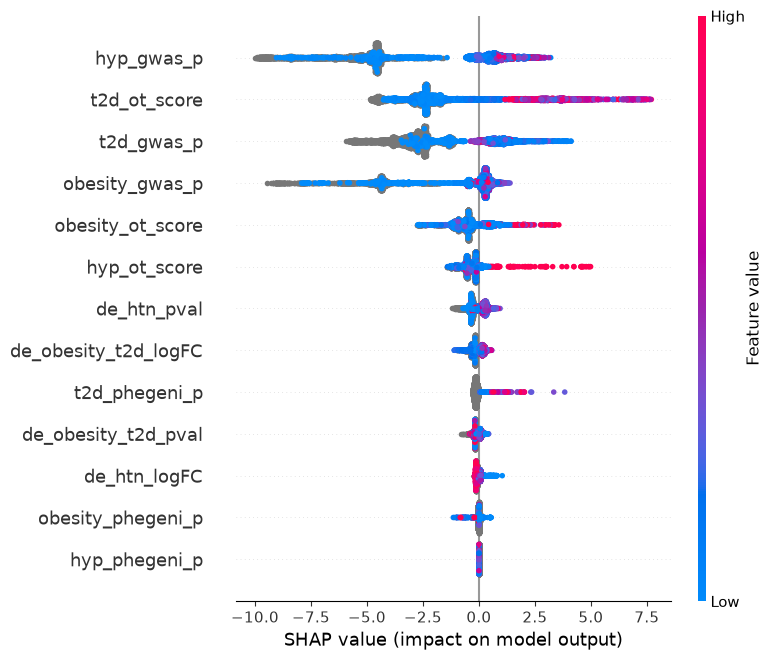

In [17]:
import shap

# use the XGBoost base learner from the stacking ensemble for SHAP (tree explainer is fast and exact)
xgb_model = stack_model_v4.named_estimators_['xgb']

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_trainval4)

import matplotlib.pyplot as plt
shap.summary_plot(shap_values, X_trainval4, show=False)
plt.tight_layout()
plt.savefig(r"C:\tri_disease_project\results\figures\shap_summary_v4.png", dpi=300, bbox_inches='tight')
plt.show()